<a href="https://colab.research.google.com/github/ahmed-abo-el3ela/assymint-of-data-science-code/blob/main/%D9%85%D8%A7%D8%B4%D9%8A%D9%86_%D9%85%D8%A7_%D9%82%D8%A8%D9%84_%D8%A7%D9%84_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris, load_breast_cancer # Corrected the typo here
import warnings
warnings.filterwarnings('ignore')

In [ ]:
data = load_breast_cancer()

In [ ]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [ ]:
data.DESCR

'.. _breast_cancer_dataset:\n\nBreast cancer wisconsin (diagnostic) dataset\n--------------------------------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 569\n\n:Number of Attributes: 30 numeric, predictive attributes and the class\n\n:Attribute Information:\n    - radius (mean of distances from center to points on the perimeter)\n    - texture (standard deviation of gray-scale values)\n    - perimeter\n    - area\n    - smoothness (local variation in radius lengths)\n    - compactness (perimeter^2 / area - 1.0)\n    - concavity (severity of concave portions of the contour)\n    - concave points (number of concave portions of the contour)\n    - symmetry\n    - fractal dimension ("coastline approximation" - 1)\n\n    The mean, standard error, and "worst" or largest (mean of the three\n    worst/largest values) of these features were computed for each image,\n    resulting in 30 features.  For instance, field 0 is Mean Radius, field\n    10 is Radius SE, field 

In [ ]:
data.DESCR.split('\n')

['.. _breast_cancer_dataset:',
 '',
 'Breast cancer wisconsin (diagnostic) dataset',
 '--------------------------------------------',
 '',
 '**Data Set Characteristics:**',
 '',
 ':Number of Instances: 569',
 '',
 ':Number of Attributes: 30 numeric, predictive attributes and the class',
 '',
 ':Attribute Information:',
 '    - radius (mean of distances from center to points on the perimeter)',
 '    - texture (standard deviation of gray-scale values)',
 '    - perimeter',
 '    - area',
 '    - smoothness (local variation in radius lengths)',
 '    - compactness (perimeter^2 / area - 1.0)',
 '    - concavity (severity of concave portions of the contour)',
 '    - concave points (number of concave portions of the contour)',
 '    - symmetry',
 '    - fractal dimension ("coastline approximation" - 1)',
 '',
 '    The mean, standard error, and "worst" or largest (mean of the three',
 '    worst/largest values) of these features were computed for each image,',
 '    resulting in 30 feature

In [ ]:
x =data.data
y=data.target

In [ ]:
df = pd.DataFrame(data=x , columns=data.feature_names)
#data ==>data \\\ columns ==> name of data
# output
df['target']=y
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
 df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [ ]:
x=df.drop('target',axis=1)
y=df['target']

#check balance

In [ ]:
df['target'].value_counts()

,count
target,
1,357
0,212


<Axes: xlabel='target', ylabel='count'>

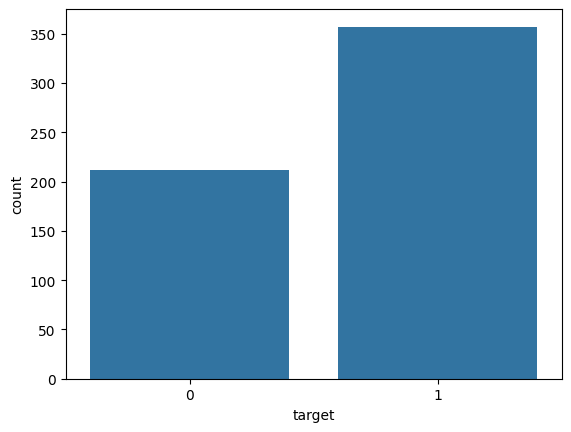

In [ ]:
sns.countplot(x='target' , data=df)

#handelling

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter
smote=SMOTE(sampling_strategy='minority' , k_neighbors=5)
x_resample,y_resample=smote.fit_resample(x,y)

In [ ]:
Counter(y_resample)


Counter({0: 357, 1: 357})

#split data

In [ ]:
x_train,y_train,x_test,y_test= train_test_split(x_resample , y_resample)

#scaling

In [ ]:
#split data
x_train, x_test, y_train, y_test = train_test_split(x_resample, y_resample)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

#شغل الديب اول سيشين DL


#build preceptron from scatch

In [ ]:
#activation_fun(segmoid)

In [ ]:
def sigmoid(x):
  return 1/ (1+ np.exp(-x))

#prepare_perceptron
4 step for this

In [ ]:
def preceptron(x,w,b):
  net =  np.dot(x,w)+b   #net(percep)
  y_pred = sigmoid(net)  #activation func(1/1-e**-net)
  new_pred = [1 if i>=.5 else 0  for i in y_pred]
  return new_pred

In [ ]:
def update_weight(w , x , y_pred , y_actual , lr):
  m = len(y)
  cost_func = 1/m *np.dot(x ,(y_pred-y_actual)) # مشتقه
  new_wight = w - lr * cost_func
  return new_wight

In [ ]:
def update_bias(w , x , y_pred , y_actual , lr):
  m = len(y)
  cost_func = 1/m* np.sum(y_pred-y_actual) # مشتقه
  bias = w - lr * cost_func
  return bias

#evaluation

In [ ]:
def accuracy_ai_deploma (y_pred , y_actual):
  return np.sum(y_pred == y_actual)/len(y_actual)

#train

In [ ]:
x_train.shape

(535, 30)

In [ ]:
def update_weight(w , x , y_pred , y_actual , lr):
  m = len(y)
  cost_func = 1/m *np.dot(x ,(y_pred-y_actual)) # مشتقه
  new_wight = w - lr * cost_func
  return new_wight

In [ ]:
weight = np.zeros(30)
lr = .001
bias = 0

for i in range (1000):
  y_pred = preceptron(x_train , weight , bias)
  weight = update_weight(weight , x_train , y_pred , y_train , lr)
  bias = update_bias(bias , x_train , y_pred , y_train , lr)

In [ ]:
weight

array([ 1.23264300e-04, -8.37189605e-05,  1.39869176e-04,  7.82632804e-05,
       -1.85046783e-05,  3.03738024e-04, -2.65267084e-04, -2.94962623e-04,
        5.27659977e-05, -1.05828643e-04, -3.45407957e-04,  4.96652465e-05,
       -1.02079391e-05, -3.71542769e-04,  1.43962578e-04,  9.60138008e-07,
        1.63977747e-04,  4.92299875e-05, -1.70832963e-05,  9.95692641e-05,
       -2.34054313e-04, -2.12186106e-04, -1.02776313e-04, -2.47156267e-04,
       -1.27804203e-04,  1.02119567e-04, -2.30069196e-04, -1.74851580e-04,
       -6.32775613e-05, -2.66770890e-05])

In [ ]:
bias

np.float64(-0.0004971962616822431)

# evaluation

In [ ]:
y_pred =  preceptron(x_test , weight , bias)
accuracy_ai_deploma(y_pred , y_test)

np.float64(0.9608938547486033)